# Calculate and add conduite size on the nodes of graph 

The size is calculated from splays or from left-right-up-down information

## Splay

If splay information exists on the nodes, then an approximation of the geometry of the conduit at the node (distance from the node to the wall) can be calculated.
This calculation is performed by projecting the splays to the plan perpendicular to the direction of conduit at this point. The direction of the conduit is assumed to be perpendicular to the bisectrice of the angle formed by the conduit before and after the node.

The cross-sectional dimensions are calculated based on the projected splay lengths in the u and v directions, 
which are perpendicular to the conduit direction at each node. Different outputs can be requested, 
including the geometric mean of the cross-section radius, the cross-section width and height, 
and the projected splay lengths in the u and v directions. The function returns a dictionary 
with the requested geometric properties for each node in the graph. 

The cross-sectional dimensions are calculated as follows:

- The cross-sectional width is calculated as the difference between the maximum and minimum projected splay lengths in the u direction.
- The cross-sectional height is calculated as the difference between the maximum and minimum projected splay lengths in the v direction.
- The geometric mean of the cross-section radius is calculated as the square root of the product of half the cross-section width and half the cross-section height.  

### Some caveats to consider:

- Depending on the survey data, some nodes may have no splays or only one splay, which can result in zero cross-sectional dimensions or biased estimates. 
- The splay measurements may not be uniformly distributed around the node, which can also affect the accuracy of the cross-sectional dimensions. 
- Some cavers measure splays in the front and back of the station, sometime far away from the station and the projection of those splays may not 
be representative of the actual cross-section.
- For nodes with degree greater than 2 (intersections), the cross-sectional dimensions are  calculated as 
the mean of the projected splay lengths, rather than the projections in the u and v directions. 

In [1]:
import networkx as nx
import sys
import os

# to import karstnet from the src folder for developpement purpose
sys.path.append("../src")
import karstnet as kn


In [2]:
path_to_yaml = '../data/006_ReveEveille_000/006_ReveEveille_000.yaml' # '../data/047_Seefeldhoele_000/047_Seefeldhoele_000.yaml'
G = kn.io_func.networkx_from_yaml(path_to_yaml)
print(f'List of node attributes attached to the graph: {kn.utils.get_node_attribute_names(G)}')

List of node attributes attached to the graph: ['pos', 'csdim', 'comments', 'fulladdress', 'splays', 'idsql', 'flags']


In [3]:
#extract and calculate all geometry information
all_dict = kn.geom.calc_conduit_dimensions(G, output = 'projections')
geommean_radius, width, height, projected_splays_u, projected_splays_v = kn.geom.calc_conduit_dimensions(G, output = 'all')

#ADD GEOMETRY INFO ON THE NODES
nx.set_node_attributes(G, geommean_radius, 'geommean_radius') 
nx.set_node_attributes(G, width, 'width') 
nx.set_node_attributes(G, height, 'height') 
nx.set_node_attributes(G, projected_splays_u, 'projected_splays_u') 
nx.set_node_attributes(G, projected_splays_v, 'projected_splays_v') 

In [12]:
conduit_directions = kn.geom.get_conduit_direction(G)
splay_vectors =kn.geom.get_splay_vectors(G)
# s = kn.geom.calc_projected_splay_lengths(conduit_directions,projected_splays)
keys = list(splay_vectors.keys())
for key in keys:
#calculate the projected splay length component in u and v direction
    #sometimes there is splays that were duplicates. 
    if key in conduit_directions:
        su_len=[]
        sv_len=[]
        if len(conduit_directions[key])>0:
            for splay_vector in splay_vectors[key]:       
                s,u,v = kn.geom.calc_projected_splay_lengths(conduit_directions[key],splay_vector,add_vector=True)
                print(u,v)

[0.56552836 0.82472885 0.        ] [ 0.65146518 -0.44671898  0.61321714]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.26263793 -0.93448075]
[0.73771866 0.67510827 0.        ] [ 0.24034777 -0.

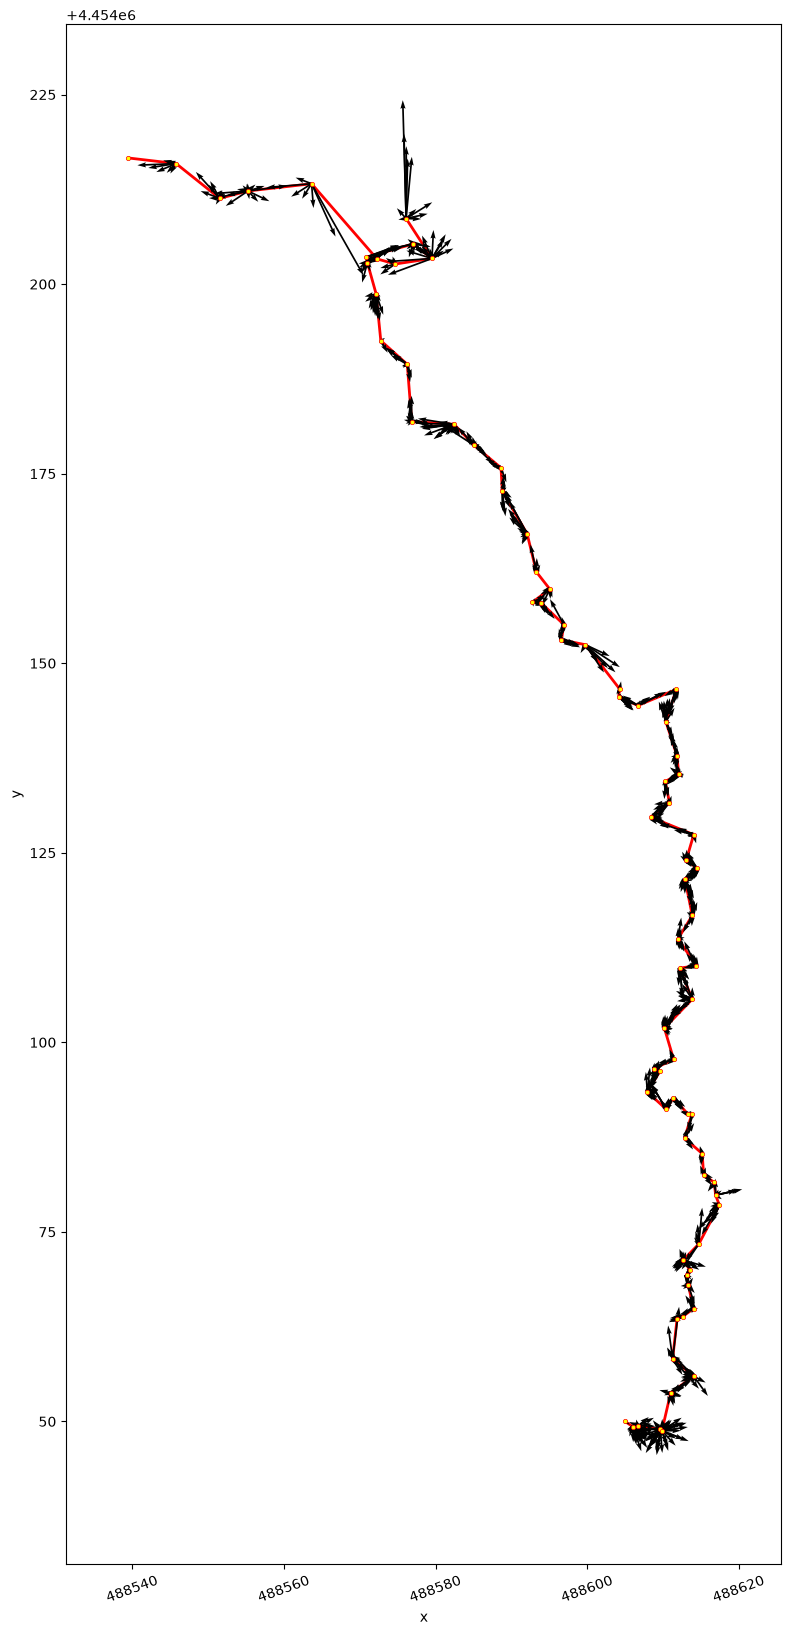

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

projected_splays = kn.geom.get_projected_splay_vectors(G)
# list_splay_vec =[value for key, value in projected_splays.items()]
# list_keys =[key for key, value in projected_splays.items()]
u = np.array([float(arr[0]) for arrays in projected_splays.values() for arr in arrays])
v = np.array([float(arr[1]) for arrays in projected_splays.values() for arr in arrays])
w = np.array([float(arr[2]) for arrays in projected_splays.values() for arr in arrays])

pos3d = kn.utils.get_pos3d(G, pos_attr='pos')
x = np.array([float(pos3d[key][0]) for key, arrays in projected_splays.items() for _ in arrays])
y = np.array([float(pos3d[key][1]) for key, arrays in projected_splays.items() for _ in arrays])
z = np.array([float(pos3d[key][2]) for key, arrays in projected_splays.items() for _ in arrays])

# Plot 2D (no node / edge property) - projection onto Oxy (default)
options = {
    'node_size'   : 10,          # node size
    'linewidths'  : 0.5,         # node border width       
    'edgecolors'  : 'red',       # node border color
    'node_color'  : 'yellow', # node color
    'width'       : 2,           # edge width
    'edge_color'  : 'red',      # edge color
    'with_labels' : False,       # show node labels ?
    # 'font_size'   : 10           # font size for labels
}

fig, ax = plt.subplots(figsize=(30, 20))

kn.view.plot_graph2d(
    G,
    plot_nodes=True, # default is True; set to False to hide nodes
    plot_edges=True, # default is True; set to False to hide edges
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)

ax.quiver(x, y, u, v)
ax.set_aspect('equal')

plt.show()

In [ ]:

direction = kn.geom.get_conduit_direction(G)
direction

In [ ]:
projected_splays =kn.geom.get_projected_splay_vectors(G)
projected_splays

In [ ]:
splay_u,splay_v = kn.geom.calc_conduit_dimensions(G, output = 'projections')

In [ ]:
splays_direction = kn.geom.get_projected_splay_direction(G)

In [ ]:
splays_direction

In [ ]:
cs_dimension = kn.geom.calc_conduit_dimensions(G, output = 'csdim')
cs_dimension = {k: v for k, v in cs_dimension.items() if not (v[0] == 0 and v[1] == 0)}
nx.set_node_attributes(G, cs_dimension, 'csdim') 

In [ ]:
cs_dimension_lrud = kn.geom.calc_csdim_from_th(G,)
#remove node with 0 with and 0 height:
cs_dimension_lrud = {k: v for k, v in cs_dimension_lrud.items() if not (v[0] == 0 and v[1] == 0)}
nx.set_node_attributes(G, cs_dimension_lrud, 'csdim')  